<b>DV Experiment 2: Data Cleaning and Transformation</b><br><br><b>Aim:</b> Clean an intentionally messy sales CSV by standardizing headers, parsing mixed dates and currency strings, deduplicating, imputing missing values, and computing Net Revenue.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def standardize_columns(frame):
    renamed = frame.copy()
    renamed.columns = [c.strip() for c in renamed.columns]
    return renamed.rename(columns={
        "Order Id": "Order_ID",
        "Cust Name": "Customer_Name",
        "Order_Dt": "Order_Date",
        "Region_Name": "Region",
        "Product Category": "Category",
        "unit_price": "Unit_Price",
        "Qty": "Quantity",
        "Disc %": "Discount_Pct",
    })

def parse_currency(series):
    return (
        series.astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
raw_df = pd.read_csv(os.path.join(data_dir, "raw_sales_dirty.csv"), keep_default_na=True)
missing_before = raw_df.isna().sum()

print(f"Raw Shape: {raw_df.shape} | Exact Duplicates: {int(raw_df.duplicated().sum())}")
print("Missing Values Before Cleaning:")
print(missing_before)

cleaned = standardize_columns(raw_df)
for col in ["Order_ID", "Customer_Name", "Region", "Category"]:
    cleaned[col] = (
        cleaned[col]
        .replace(["", "N/A", "NA", "null"], np.nan)
        .astype("string")
        .str.strip()
    )

cleaned["Region"] = cleaned["Region"].str.title()
cleaned["Category"] = cleaned["Category"].str.title()
cleaned["Customer_Name"] = cleaned["Customer_Name"].fillna("Guest Customer")
cleaned["Region"] = cleaned["Region"].fillna(cleaned["Region"].mode()[0])

Raw Shape: (68, 8) | Exact Duplicates: 4
Missing Values Before Cleaning:
 Order Id            0
Cust Name            3
Order_Dt             0
Region_Name          2
Product Category     0
unit_price           0
Qty                  4
Disc %               3
dtype: int64


In [3]:
cleaned["Order_Date"] = pd.to_datetime(cleaned["Order_Date"], format="mixed", dayfirst=True)
cleaned["Unit_Price"] = parse_currency(cleaned["Unit_Price"])

cleaned = cleaned.drop_duplicates(subset=["Order_ID"]).reset_index(drop=True)
cleaned["Quantity"] = cleaned["Quantity"].fillna(cleaned["Quantity"].median()).astype(int)
cleaned["Discount_Pct"] = cleaned["Discount_Pct"].fillna(0.0).astype(float)

cleaned["Gross_Sales"] = np.round(cleaned["Quantity"] * cleaned["Unit_Price"], 2)
cleaned["Discount_Value"] = np.round(cleaned["Gross_Sales"] * (cleaned["Discount_Pct"] / 100.0), 2)
cleaned["Net_Revenue"] = np.round(cleaned["Gross_Sales"] - cleaned["Discount_Value"], 2)
cleaned["Order_Quarter"] = cleaned["Order_Date"].dt.to_period("Q").astype(str)

cleaned.to_csv(os.path.join(data_dir, "cleaned_sales.csv"), index=False)

col_map = {
    " Order Id ": "Order_ID",
    "Cust Name": "Customer_Name",
    "Order_Dt": "Order_Date",
    "Region_Name": "Region",
    "Product Category ": "Category",
    "unit_price": "Unit_Price",
    "Qty": "Quantity",
    "Disc %": "Discount_Pct",
}
missing_after = cleaned[[col_map[c] for c in missing_before.index]].isna().sum()

print("\nCleaned Shape:", cleaned.shape)
print("Sample Transformed Records:")
print(cleaned[["Order_ID", "Order_Date", "Customer_Name", "Region", "Net_Revenue", "Order_Quarter"]].head(6).to_string(index=False))


Cleaned Shape: (64, 12)
Sample Transformed Records:
Order_ID Order_Date   Customer_Name Region  Net_Revenue Order_Quarter
INV-2101 2024-03-01    Aarav Sharma  South      4640.03        2024Q1
INV-2102 2024-07-06       Diya Nair   West      2512.94        2024Q3
INV-2103 2024-09-26  Kabir Malhotra  South      3097.43        2024Q3
INV-2104 2024-04-26  Guest Customer   West      2927.46        2024Q2
INV-2105 2024-09-23  Kabir Malhotra  South      7053.50        2024Q3
INV-2106 2024-03-02 Riya Chatterjee   West      5469.18        2024Q1


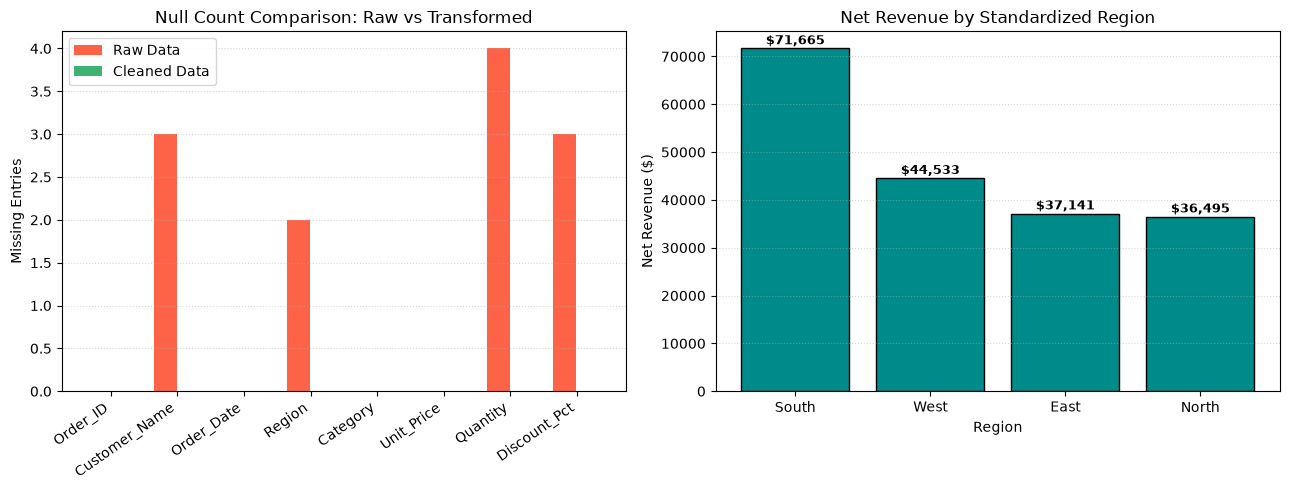

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

xpos = np.arange(len(missing_after))
ax[0].bar(xpos - 0.18, missing_before.values, width=0.35, color="tomato", label="Raw Data")
ax[0].bar(xpos + 0.18, missing_after.values, width=0.35, color="mediumseagreen", label="Cleaned Data")
ax[0].set_xticks(xpos)
ax[0].set_xticklabels(list(missing_after.index), rotation=35, ha="right")
ax[0].set_title("Null Count Comparison: Raw vs Transformed")
ax[0].set_ylabel("Missing Entries")
ax[0].legend()
ax[0].grid(True, axis="y", linestyle=":", alpha=0.5)

reg_rev = cleaned.groupby("Region", as_index=False)["Net_Revenue"].sum().sort_values("Net_Revenue", ascending=False)
ax[1].bar(reg_rev["Region"], reg_rev["Net_Revenue"], color="darkcyan", edgecolor="black")
for i, val in enumerate(reg_rev["Net_Revenue"]):
    ax[1].text(i, val + 250, f"${val:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax[1].set_title("Net Revenue by Standardized Region")
ax[1].set_xlabel("Region")
ax[1].set_ylabel("Net Revenue ($)")
ax[1].grid(True, axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> All missing counts and duplicate rows drop to zero after transformation, enabling clean regional revenue aggregation.